[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L6/BA_L6_spill/BA_L6_spill.ipynb)

# BA_L6_spill: Diebold-Yilmaz spillovers among 8 coins

*Quantlet of Lecture 6, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Diebold-Yilmaz spillover table of 8 large cryptocurrencies from a vector autoregression with lag chosen by AIC and the generalised forecast-error variance decomposition at a 10-day horizon (EODHD daily log returns, January 2021 - October 2026); rolling total spillover index on 200-day windows with a VAR(2), and full-sample net spillovers.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Data

Daily closes of 19 coins from EODHD (course repository, `data/market`), 1 January 2021 to 23 October 2026.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [5]:
COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()           # daily log returns in %
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


### Method

A vector autoregression (VAR) on $N$ return series, $\mathbf r_t = \sum_{l=1}^{p}\Phi_l \mathbf r_{t-l} + \boldsymbol\varepsilon_t$, has the
moving-average (MA) form $\mathbf r_t = \sum_{h \ge 0} A_h \boldsymbol\varepsilon_{t-h}$ with $\Sigma = V(\boldsymbol\varepsilon_t)$.
The generalised forecast-error variance decomposition (FEVD) of Pesaran and Shin at horizon $H$ is

$$ \theta_{ij}(H) = \frac{\sigma_{jj}^{-1}\sum_{h=0}^{H-1}\big(\mathbf e_i' A_h \Sigma \mathbf e_j\big)^2}{\sum_{h=0}^{H-1}\mathbf e_i' A_h \Sigma A_h' \mathbf e_i}, \qquad \tilde\theta_{ij} = \frac{\theta_{ij}}{\sum_j \theta_{ij}}, $$

the share of coin $i$'s $H$-day forecast-error variance due to shocks in coin $j$. The spillover indices of Diebold and Yilmaz (2012), in %:

$$ S = \frac{100}{N}\sum_{i \neq j}\tilde\theta_{ij}, \qquad \mathrm{TO}_j = 100\sum_{i \neq j}\tilde\theta_{ij}, \qquad \mathrm{FROM}_i = 100\sum_{j \neq i}\tilde\theta_{ij}, \qquad \mathrm{NET}_i = \mathrm{TO}_i - \mathrm{FROM}_i . $$

Full sample: lag order chosen by the Akaike information criterion (AIC, at most 5 lags), $H = 10$ days. In the table the row is the
**receiver** and the column the **source** of the shocks.

In [6]:
from statsmodels.tsa.api import VAR

SUB = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'LTC']


def gfevd(res, H=10):
    """Generalised FEVD (Pesaran-Shin), rows normalised to 1."""
    Sig = np.asarray(res.sigma_u)
    A = res.ma_rep(H - 1)                                        # A_0 .. A_{H-1}
    k = Sig.shape[0]
    th = np.zeros((k, k))
    for i in range(k):
        den = sum(A[h][i] @ Sig @ A[h][i] for h in range(H))
        for j in range(k):
            th[i, j] = sum((A[h][i] @ Sig[:, j]) ** 2 for h in range(H)) / Sig[j, j] / den
    return th / th.sum(axis=1, keepdims=True)


Y = R[SUB]
vr = VAR(Y).fit(maxlags=5, ic='aic')
TH = gfevd(vr)
total = 100 * (TH.sum() - np.trace(TH)) / len(SUB)
to_ = 100 * (TH.sum(axis=0) - np.diag(TH))
from_ = 100 * (TH.sum(axis=1) - np.diag(TH))
net = pd.Series(to_ - from_, index=SUB)
tab = pd.DataFrame(100 * TH, index=SUB, columns=SUB)
tab['FROM'] = from_
tab.loc['TO'] = list(to_) + [total]
tab.loc['NET'] = list(net) + [np.nan]
print(f'VAR lag order chosen by AIC: {vr.k_ar}; forecast horizon H = 10 days')
print('Spillover table (%), row = receiver, column = source of the shocks:')
print(tab.round(1).to_string())
print(f'\nTotal spillover index S = mean of the FROM column = {total:.1f}%')

VAR lag order chosen by AIC: 5; forecast horizon H = 10 days
Spillover table (%), row = receiver, column = source of the shocks:
       BTC   ETH   XRP   BNB   SOL   ADA  DOGE   LTC  FROM
BTC   23.3  16.0   9.4  10.6  10.0  11.3   7.3  12.0  76.7
ETH   15.3  22.5   9.5  10.5  10.9  11.8   6.9  12.5  77.5
XRP   11.2  11.8  28.1   9.0   8.6  13.0   5.9  12.4  71.9
BNB   12.7  13.3   8.9  28.4  10.4  10.0   4.9  11.3  71.6
SOL   12.1  13.8   8.5  10.5  28.3  11.6   5.7   9.4  71.7
ADA   12.1  13.2  11.5   8.7  10.3  25.0   7.2  12.0  75.0
DOGE  11.4  11.1   7.3   6.0   7.1  10.4  36.4  10.2  63.6
LTC   12.8  14.0  11.0   9.9   8.3  11.9   7.1  25.0  75.0
TO    87.7  93.2  66.1  65.4  65.7  80.0  45.0  80.0  72.9
NET   11.0  15.7  -5.8  -6.3  -6.0   5.0 -18.6   5.0   NaN

Total spillover index S = mean of the FROM column = 72.9%


### Spillovers through time

The total spillover index is re-estimated on rolling 200-day windows, moved forward 10 days at a time, with a VAR(2) in every window
(a fixed lag keeps the windows comparable). Dotted lines: Terra collapse (May 2022), FTX collapse (November 2022), spot Bitcoin
exchange-traded funds (ETFs, January 2024). The right panel shows the full-sample NET spillovers (positive = net transmitter of shocks).

             total spillover index (%) window ending
lowest                            65.2    2021-07-20
highest                           83.5    2026-05-25
last window                       80.4    2026-10-22


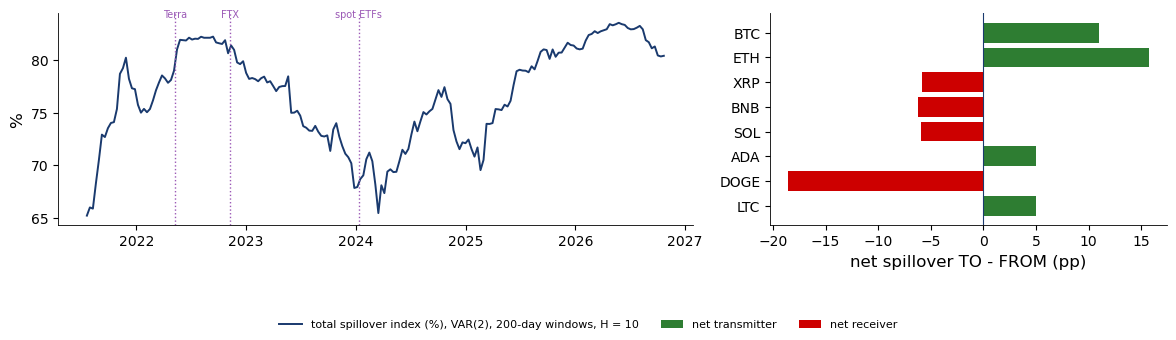

In [7]:
roll = {}
for k in range(200, len(Y) + 1, 10):
    y = Y.iloc[k - 200:k]
    th = gfevd(VAR(y).fit(2))
    roll[y.index[-1]] = 100 * (th.sum() - np.trace(th)) / len(SUB)
roll = pd.Series(roll)
print(pd.DataFrame({'total spillover index (%)': [roll.min(), roll.max(), roll.iloc[-1]],
                    'window ending': [roll.idxmin().date(), roll.idxmax().date(), roll.index[-1].date()]},
                   index=['lowest', 'highest', 'last window']).round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(roll.index, roll, color=BLUE, lw=1.4, label='total spillover index (%), VAR(2), 200-day windows, H = 10')
for d0, lab in [('2022-05-09', 'Terra'), ('2022-11-08', 'FTX'), ('2024-01-11', 'spot ETFs')]:
    ax[0].axvline(pd.Timestamp(d0), color=ETH, ls=':', lw=1)
    ax[0].text(pd.Timestamp(d0), roll.max() + 0.5, lab, fontsize=7, color=ETH, ha='center')
ax[0].set_ylabel('%')
ax[1].barh(net.index[::-1], net.values[::-1], color=[GREEN if v > 0 else RED for v in net.values[::-1]])
ax[1].axvline(0, color=BLUE, lw=0.8); ax[1].set_xlabel('net spillover TO - FROM (pp)')
for col_, lb_ in [(GREEN, 'net transmitter'), (RED, 'net receiver')]:
    ax[1].bar([0], [0], color=col_, label=lb_, width=0)
slide_fig(fig, 'ba_l6_spill', 0.15, ncol=3)